# End-to-End Virtual Screening Molecule Generator
### Parent compound → functional-group analogues → descriptor filtering → CSV/SDF export

This Google Colab notebook generates candidate analogues by replacing **aromatic C–H positions** in a parent molecule with selected substituents. It deduplicates structures, calculates molecular descriptors, applies configurable preliminary filters, visualizes molecules, and exports CSV/SDF files.

**Important:** This is structure enumeration, not a biological activity predictor. The transformations target aromatic C–H sites only; they do not automatically replace arbitrary functional groups or guarantee synthetic feasibility.

🎥 Future Omics — Bioinformatics Made Easy
For more bioinformatics, genomics, and omics tutorials:

📺 Future Omics — Bioinformatics Made Easy 📺 Future Omics — Bioinformatics Made Easy https://www.youtube.com/@Bioinformatics_Made_Easy?sub_confirmation=1

The channel focuses on simplified bioinformatics and omics tutorials for students, researchers, and life-science learners.

## 1. Install dependencies
Run this cell first.

In [ ]:
%pip -q install rdkit pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 22.8 MB/s eta 0:00:00


## 2. Configure the parent compound and library

The example uses aspirin for demonstration. Replace `PARENT_SMILES` with your own compound. `MAX_SUBSTITUTIONS = 1` generates single substitutions; set it to `2` to explore sequential two-substitution combinations. Larger values can cause rapid library growth.

In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, Crippen, Lipinski, rdMolDescriptors, QED, Draw
from IPython.display import display
import pandas as pd
from pathlib import Path

PARENT_NAME = "Aspirin_demo"
PARENT_SMILES = "CC(=O)Oc1ccccc1C(=O)O"  # Replace with your parent compound SMILES

FUNCTIONAL_GROUPS = {
    "Fluoro": "[cH:1]>>[c:1]F",
    "Chloro": "[cH:1]>>[c:1]Cl",
    "Methyl": "[cH:1]>>[c:1]C",
    "Methoxy": "[cH:1]>>[c:1]OC",
    "Hydroxyl": "[cH:1]>>[c:1]O",
    "Amino": "[cH:1]>>[c:1]N",
    "Cyano": "[cH:1]>>[c:1]C#N",
    "Carboxamide": "[cH:1]>>[c:1]C(N)=O",
    "Trifluoromethyl": "[cH:1]>>[c:1]C(F)(F)F",
    "Acetyl": "[cH:1]>>[c:1]C(C)=O",
}

MAX_SUBSTITUTIONS = 1
MAX_MOLECULES = 5000

# Preliminary filters (editable; not efficacy or safety criteria)
MW_MAX = 500
LOGP_MAX = 5
HBD_MAX = 5
HBA_MAX = 10
TPSA_MAX = 140

OUTPUT_DIR = Path("/content/virtual_screening_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration loaded.")
print(f"Functional groups: {len(FUNCTIONAL_GROUPS)}")
print(f"Maximum substitution rounds: {MAX_SUBSTITUTIONS}")

Configuration loaded.
Functional groups: 10
Maximum substitution rounds: 1


## 3. Validate and standardize the parent molecule
The notebook canonicalizes SMILES but does not perform full tautomer, salt, or protonation-state standardization.

Parent name: Aspirin_demo
Canonical SMILES: CC(=O)Oc1ccccc1C(=O)O


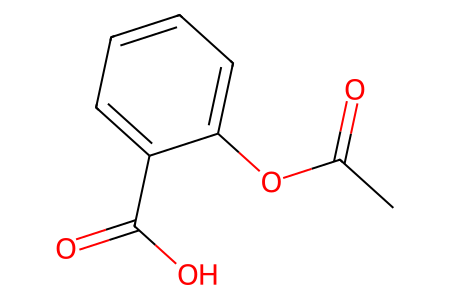

In [ ]:
parent = Chem.MolFromSmiles(PARENT_SMILES)
if parent is None:
    raise ValueError("Parent SMILES could not be parsed. Check the input.")

parent = Chem.RemoveHs(parent)
parent_smiles = Chem.MolToSmiles(parent, canonical=True)

print("Parent name:", PARENT_NAME)
print("Canonical SMILES:", parent_smiles)
display(Draw.MolToImage(parent, size=(450, 300)))

## 4. Define descriptor and validation functions

In [ ]:
def safe_sanitize(mol):
    # Return a sanitized molecule, or None if invalid.
    if mol is None:
        return None
    try:
        mol = Chem.Mol(mol)
        Chem.SanitizeMol(mol)
        return Chem.RemoveHs(mol)
    except Exception:
        return None

def molecule_descriptors(mol):
    return {
        "Molecular_Weight": round(Descriptors.MolWt(mol), 3),
        "Exact_Mass": round(Descriptors.ExactMolWt(mol), 4),
        "LogP": round(Crippen.MolLogP(mol), 3),
        "TPSA": round(rdMolDescriptors.CalcTPSA(mol), 3),
        "HBD": int(Lipinski.NumHDonors(mol)),
        "HBA": int(Lipinski.NumHAcceptors(mol)),
        "Rotatable_Bonds": int(Lipinski.NumRotatableBonds(mol)),
        "Heavy_Atoms": int(mol.GetNumHeavyAtoms()),
        "Formal_Charge": int(Chem.GetFormalCharge(mol)),
        "QED": round(QED.qed(mol), 3),
        "Ring_Count": int(rdMolDescriptors.CalcNumRings(mol)),
    }

def canonical_smiles(mol):
    return Chem.MolToSmiles(mol, canonical=True)

## 5. Build the functional-group reaction library
Each reaction is compiled from SMARTS. Invalid reactions are reported and skipped.

In [ ]:
compiled_reactions = {}
for group_name, reaction_smarts in FUNCTIONAL_GROUPS.items():
    try:
        rxn = AllChem.ReactionFromSmarts(reaction_smarts)
        if rxn is None:
            print(f"Skipping invalid reaction SMARTS for {group_name}: {reaction_smarts}")
        else:
            compiled_reactions[group_name] = rxn
    except Exception as exc:
        print(f"Could not compile {group_name}: {exc}")

if not compiled_reactions:
    raise RuntimeError("No functional-group reactions could be compiled.")

print(f"Compiled {len(compiled_reactions)} reactions.")

Compiled 10 reactions.


## 6. Generate analogues

The enumerator starts from the parent and applies one reaction per round. Canonical SMILES remove duplicates. For multi-substitution mode, each round applies each transformation to molecules from the previous round.

**Caution:** This can generate many candidates. The safety cap stops expansion at `MAX_MOLECULES`.

In [ ]:
records_by_smiles = {
    parent_smiles: {
        "Molecule_ID": "PARENT",
        "Parent_Name": PARENT_NAME,
        "Modification": "Unmodified",
        "Substitution_Round": 0,
        "SMILES": parent_smiles,
        **molecule_descriptors(parent),
    }
}
frontier = [(parent, "Unmodified", 0)]

for round_num in range(1, MAX_SUBSTITUTIONS + 1):
    next_frontier = []
    print(f"Generating round {round_num} ...")
    stop = False

    for source_mol, source_label, _ in frontier:
        for group_name, rxn in compiled_reactions.items():
            try:
                products = rxn.RunReactants((source_mol,))
            except Exception:
                continue

            for product_tuple in products:
                product = safe_sanitize(product_tuple[0])
                if product is None:
                    continue
                smi = canonical_smiles(product)
                if smi in records_by_smiles:
                    continue

                if len(records_by_smiles) >= MAX_MOLECULES:
                    print("Reached MAX_MOLECULES safety cap.")
                    stop = True
                    break

                new_label = group_name if source_label == "Unmodified" else f"{source_label} + {group_name}"
                mol_id = f"VS_{len(records_by_smiles):05d}"
                records_by_smiles[smi] = {
                    "Molecule_ID": mol_id,
                    "Parent_Name": PARENT_NAME,
                    "Modification": new_label,
                    "Substitution_Round": round_num,
                    "SMILES": smi,
                    **molecule_descriptors(product),
                }
                next_frontier.append((product, new_label, round_num))

            if stop:
                break
        if stop:
            break

    frontier = next_frontier
    print(f"Unique molecules so far: {len(records_by_smiles)}")
    if not frontier or stop:
        break

library_df = pd.DataFrame(records_by_smiles.values()).drop_duplicates(subset="SMILES").reset_index(drop=True)
print("\nGeneration complete.")
print("Total unique structures, including parent:", len(library_df))
print("New analogues:", max(0, len(library_df) - 1))
display(library_df.head(10))

Generating round 1 ...
Unique molecules so far: 41

Generation complete.
Total unique structures, including parent: 41
New analogues: 40


,Molecule_ID,Parent_Name,Modification,Substitution_Round,SMILES,Molecular_Weight,Exact_Mass,LogP,TPSA,HBD,HBA,Rotatable_Bonds,Heavy_Atoms,Formal_Charge,QED,Ring_Count
0,PARENT,Aspirin_demo,Unmodified,0,CC(=O)Oc1ccccc1C(=O)O,180.159,180.0423,1.310,63.6,1,3,2,13,0,0.550,1
1,VS_00001,Aspirin_demo,Fluoro,1,CC(=O)Oc1c(F)cccc1C(=O)O,198.149,198.0328,1.449,63.6,1,3,2,14,0,0.577,1
2,VS_00002,Aspirin_demo,Fluoro,1,CC(=O)Oc1cc(F)ccc1C(=O)O,198.149,198.0328,1.449,63.6,1,3,2,14,0,0.577,1
3,VS_00003,Aspirin_demo,Fluoro,1,CC(=O)Oc1ccc(F)cc1C(=O)O,198.149,198.0328,1.449,63.6,1,3,2,14,0,0.577,1
4,VS_00004,Aspirin_demo,Fluoro,1,CC(=O)Oc1cccc(F)c1C(=O)O,198.149,198.0328,1.449,63.6,1,3,2,14,0,0.577,1
5,VS_00005,Aspirin_demo,Chloro,1,CC(=O)Oc1c(Cl)cccc1C(=O)O,214.604,214.0033,1.963,63.6,1,3,2,14,0,0.604,1
6,VS_00006,Aspirin_demo,Chloro,1,CC(=O)Oc1cc(Cl)ccc1C(=O)O,214.604,214.0033,1.964,63.6,1,3,2,14,0,0.604,1
7,VS_00007,Aspirin_demo,Chloro,1,CC(=O)Oc1ccc(Cl)cc1C(=O)O,214.604,214.0033,1.963,63.6,1,3,2,14,0,0.604,1
8,VS_00008,Aspirin_demo,Chloro,1,CC(=O)Oc1cccc(Cl)c1C(=O)O,214.604,214.0033,1.963,63.6,1,3,2,14,0,0.604,1
9,VS_00009,Aspirin_demo,Methyl,1,CC(=O)Oc1c(C)cccc1C(=O)O,194.186,194.0579,1.619,63.6,1,3,2,14,0,0.574,1


## 7. Apply configurable preliminary filters
These are heuristic triage criteria, not proof of activity, safety, or oral bioavailability.

In [ ]:
library_df["Pass_Lipinski_4of5"] = (
    (library_df["Molecular_Weight"] <= MW_MAX).astype(int)
    + (library_df["LogP"] <= LOGP_MAX).astype(int)
    + (library_df["HBD"] <= HBD_MAX).astype(int)
    + (library_df["HBA"] <= HBA_MAX).astype(int)
) >= 4

library_df["Pass_TPSA_Cutoff"] = library_df["TPSA"] <= TPSA_MAX
library_df["Pass_Preliminary_Filters"] = (
    library_df["Pass_Lipinski_4of5"] & library_df["Pass_TPSA_Cutoff"]
)
filtered_df = library_df[library_df["Pass_Preliminary_Filters"]].copy()

print(f"All unique structures: {len(library_df)}")
print(f"Passing preliminary filters: {len(filtered_df)}")
display(filtered_df.sort_values("QED", ascending=False).head(20))

All unique structures: 41
Passing preliminary filters: 41


,Molecule_ID,Parent_Name,Modification,Substitution_Round,SMILES,Molecular_Weight,Exact_Mass,LogP,TPSA,HBD,HBA,Rotatable_Bonds,Heavy_Atoms,Formal_Charge,QED,Ring_Count,Pass_Lipinski_4of5,Pass_TPSA_Cutoff,Pass_Preliminary_Filters
33,VS_00033,Aspirin_demo,Trifluoromethyl,1,CC(=O)Oc1c(C(=O)O)cccc1C(F)(F)F,248.156,248.0296,2.329,63.60,1,3,2,17,0,0.644,1,True,True,True
36,VS_00036,Aspirin_demo,Trifluoromethyl,1,CC(=O)Oc1cccc(C(F)(F)F)c1C(=O)O,248.156,248.0296,2.329,63.60,1,3,2,17,0,0.644,1,True,True,True
35,VS_00035,Aspirin_demo,Trifluoromethyl,1,CC(=O)Oc1ccc(C(F)(F)F)cc1C(=O)O,248.156,248.0296,2.329,63.60,1,3,2,17,0,0.644,1,True,True,True
34,VS_00034,Aspirin_demo,Trifluoromethyl,1,CC(=O)Oc1cc(C(F)(F)F)ccc1C(=O)O,248.156,248.0296,2.329,63.60,1,3,2,17,0,0.644,1,True,True,True
8,VS_00008,Aspirin_demo,Chloro,1,CC(=O)Oc1cccc(Cl)c1C(=O)O,214.604,214.0033,1.963,63.60,1,3,2,14,0,0.604,1,True,True,True
6,VS_00006,Aspirin_demo,Chloro,1,CC(=O)Oc1cc(Cl)ccc1C(=O)O,214.604,214.0033,1.964,63.60,1,3,2,14,0,0.604,1,True,True,True
7,VS_00007,Aspirin_demo,Chloro,1,CC(=O)Oc1ccc(Cl)cc1C(=O)O,214.604,214.0033,1.963,63.60,1,3,2,14,0,0.604,1,True,True,True
5,VS_00005,Aspirin_demo,Chloro,1,CC(=O)Oc1c(Cl)cccc1C(=O)O,214.604,214.0033,1.963,63.60,1,3,2,14,0,0.604,1,True,True,True
16,VS_00016,Aspirin_demo,Methoxy,1,COc1cccc(OC(C)=O)c1C(=O)O,210.185,210.0528,1.319,72.83,1,4,3,15,0,0.601,1,True,True,True
14,VS_00014,Aspirin_demo,Methoxy,1,COc1ccc(C(=O)O)c(OC(C)=O)c1,210.185,210.0528,1.319,72.83,1,4,3,15,0,0.601,1,True,True,True


## 8. Visualize selected generated structures

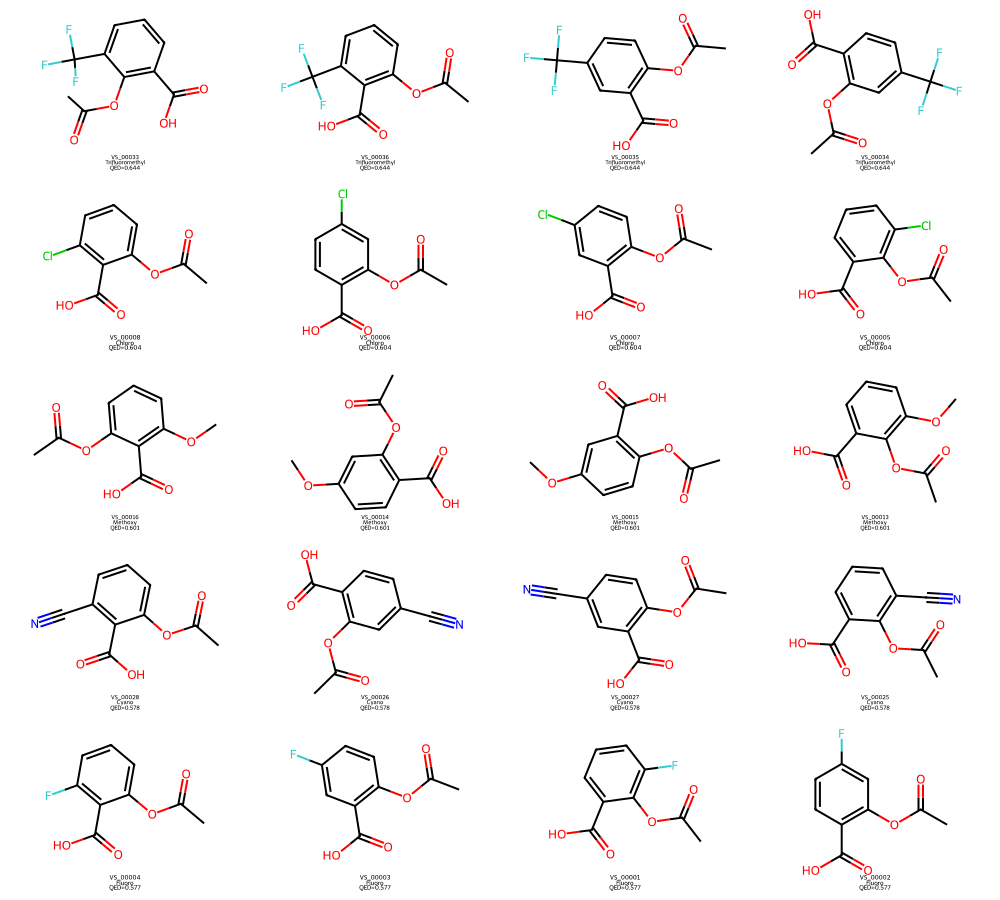

In [ ]:
preview_df = library_df.sort_values("QED", ascending=False).head(20)
preview_mols, preview_legends = [], []

for _, row in preview_df.iterrows():
    mol = Chem.MolFromSmiles(row["SMILES"])
    if mol is not None:
        preview_mols.append(mol)
        preview_legends.append(f'{row["Molecule_ID"]}\n{row["Modification"]}\nQED={row["QED"]}')

if preview_mols:
    display(Draw.MolsToGridImage(
        preview_mols, legends=preview_legends,
        molsPerRow=4, subImgSize=(250, 180), useSVG=True
    ))
else:
    print("No structures available to visualize.")

## 9. Export CSV and SDF files
The CSV files support tabular analysis; SDF files preserve molecular structures and properties.

In [ ]:
all_csv = OUTPUT_DIR / "virtual_screening_library.csv"
filtered_csv = OUTPUT_DIR / "filtered_virtual_screening_library.csv"
all_sdf = OUTPUT_DIR / "virtual_screening_library.sdf"
filtered_sdf = OUTPUT_DIR / "filtered_virtual_screening_library.sdf"

library_df.to_csv(all_csv, index=False)
filtered_df.to_csv(filtered_csv, index=False)

def write_sdf(dataframe, path):
    writer = Chem.SDWriter(str(path))
    try:
        for _, row in dataframe.iterrows():
            mol = Chem.MolFromSmiles(row["SMILES"])
            if mol is None:
                continue
            mol.SetProp("_Name", str(row["Molecule_ID"]))
            for col in dataframe.columns:
                if col == "SMILES" or pd.isna(row[col]):
                    continue
                mol.SetProp(str(col), str(row[col]))
            writer.write(mol)
    finally:
        writer.close()

write_sdf(library_df, all_sdf)
write_sdf(filtered_df, filtered_sdf)

for path in [all_csv, filtered_csv, all_sdf, filtered_sdf]:
    print(f"{path.name}: {path.stat().st_size:,} bytes")

virtual_screening_library.csv: 5,234 bytes
filtered_virtual_screening_library.csv: 5,234 bytes
virtual_screening_library.sdf: 76,379 bytes
filtered_virtual_screening_library.sdf: 76,379 bytes


## 10. Download output files from Google Colab

In [ ]:
from google.colab import files

for path in [all_csv, filtered_csv, all_sdf, filtered_sdf]:
    files.download(str(path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Save a summary report

In [ ]:
summary = {
    "Parent_Name": PARENT_NAME,
    "Parent_SMILES_Input": PARENT_SMILES,
    "Parent_Canonical_SMILES": parent_smiles,
    "Functional_Groups_Used": ", ".join(compiled_reactions.keys()),
    "Max_Substitution_Rounds": MAX_SUBSTITUTIONS,
    "Total_Unique_Structures_Including_Parent": int(len(library_df)),
    "Generated_Analogues_Excluding_Parent": int(max(0, len(library_df) - 1)),
    "Passed_Preliminary_Filters": int(len(filtered_df)),
    "Note": "Preliminary computational triage only; not a prediction of biological activity or safety."
}
summary_df = pd.DataFrame([summary])
summary_path = OUTPUT_DIR / "virtual_screening_summary.csv"
summary_df.to_csv(summary_path, index=False)
display(summary_df)
files.download(str(summary_path))

,Parent_Name,Parent_SMILES_Input,Parent_Canonical_SMILES,Functional_Groups_Used,Max_Substitution_Rounds,Total_Unique_Structures_Including_Parent,Generated_Analogues_Excluding_Parent,Passed_Preliminary_Filters,Note
0,Aspirin_demo,CC(=O)Oc1ccccc1C(=O)O,CC(=O)Oc1ccccc1C(=O)O,"Fluoro, Chloro, Methyl, Methoxy, Hydroxyl, Ami...",1,41,40,41,Preliminary computational triage only; not a p...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Recommended next steps and troubleshooting

1. Verify parent structure, stereochemistry, protonation state, and salt handling.
2. Choose substitution sites deliberately; indiscriminate aromatic substitution can create chemically implausible or synthetically inaccessible molecules.
3. Review reactive/toxicophores, stability, and synthetic accessibility.
4. For target-based screening, prepare protein and ligands consistently before docking.
5. Validate docking or ML ranking with known actives, decoys, and controls.
6. Treat all generated molecules as hypotheses until experimentally validated.

**No analogues generated?** The parent may have no aromatic C–H sites matching `[cH]`, or the selected transformations may not apply. This notebook does not handle substitutions on aliphatic atoms or arbitrary functional-group replacement.